# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 **without ImageNet pretraining and without tuning** (`NO_TUNING_ARCH_HYPERPARAMS["resnet18"]`), then saves its results and weights to disk for the results notebook. This is the baseline role AlexNet used to play — see `wwtw_utils.py`'s `ARCH_HYPERPARAMS` comment for why the baseline is now the *same* architecture as the tuned, pretrained `resnet18` run rather than a different one.


In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 947 | Val: 229 | Test: 567


## Build dataloaders + class weights for this architecture

In [2]:
cfg = NO_TUNING_ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model (ResNet-18, trained from scratch)

In [3]:
# ---------------------------------------------------------
# Define the CNN (ResNet-18, trained from scratch — no ImageNet weights)
# ---------------------------------------------------------
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18 (scratch)] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.1044 acc 0.415 | val loss 1.0976 acc 0.389 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 1.0811 acc 0.436 | val loss 0.9521 acc 0.594 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 1.0288 acc 0.565 | val loss 0.8755 acc 0.672 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.9710 acc 0.567 | val loss 0.9437 acc 0.563


...

[ResNet-18 (scratch)] Epoch  58/100 | LR: 1.00e-07 | train loss 0.6977 acc 0.720 | val loss 0.6936 acc 0.721


[ResNet-18 (scratch)] Epoch  59/100 | LR: 1.00e-07 | train loss 0.6625 acc 0.735 | val loss 0.6590 acc 0.721


[ResNet-18 (scratch)] Epoch  60/100 | LR: 1.00e-08 | train loss 0.6624 acc 0.735 | val loss 0.6501 acc 0.738


[ResNet-18 (scratch)] Epoch  61/100 | LR: 1.00e-08 | train loss 0.6876 acc 0.718 | val loss 0.6536 acc 0.734


[ResNet-18 (scratch)] Epoch  62/100 | LR: 1.00e-08 | train loss 0.6966 acc 0.714 | val loss 0.6486 acc 0.716

[ResNet-18 (scratch)] No val loss improvement for 10 epochs — stopping early at epoch 62.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.6372)


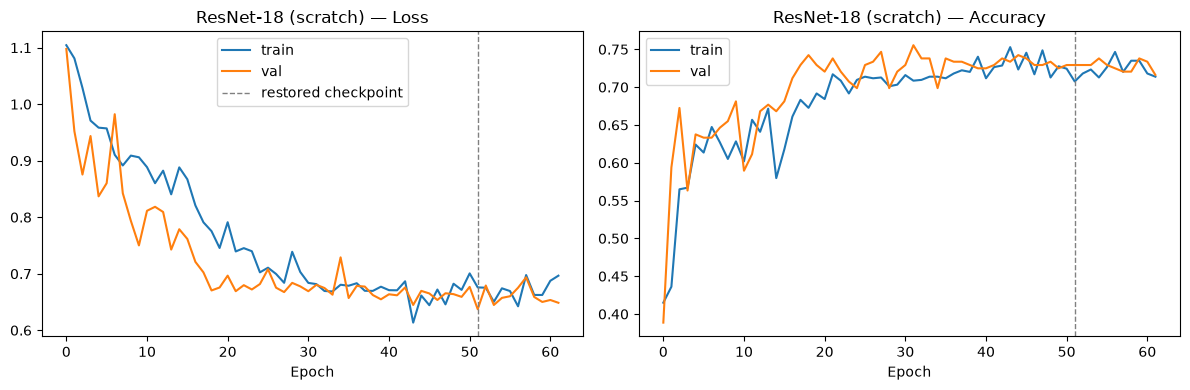

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.781


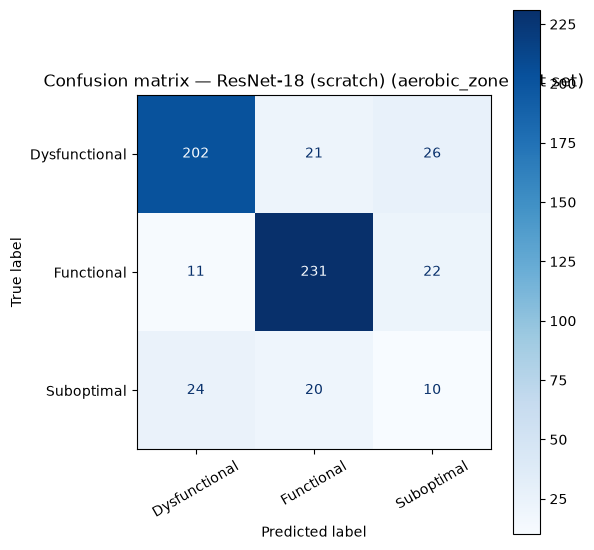

               precision    recall  f1-score   support

Dysfunctional      0.852     0.811     0.831       249
   Functional      0.849     0.875     0.862       264
   Suboptimal      0.172     0.185     0.179        54

     accuracy                          0.781       567
    macro avg      0.625     0.624     0.624       567
 weighted avg      0.786     0.781     0.783       567



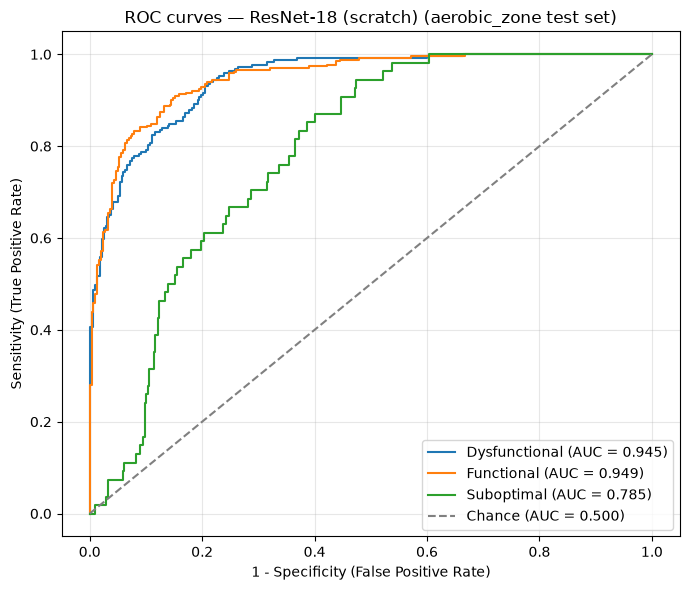

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.945
  Functional     : 0.949
  Suboptimal     : 0.785

Mean AUC (over 3/3 classes with test examples): 0.893


(np.float64(0.781305114638448),
 {'Dysfunctional': 0.9446338814377006,
  'Functional': 0.9487573757375738,
  'Suboptimal': 0.7854667533030106})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet18_scratch_chronological.pkl


Saved model weights to ../models/pad/aerobic_zone_resnet18_scratch_cnn.pt
